<a href="https://colab.research.google.com/github/vhvaldiviesor/Programacion-para-analitica-descriptiva-y-predictiva/blob/main/269711_ArbolDecisionRegresion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: Árbol de Decisión para Regresión

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**

**Nombre: Victor Hugo Valdivieso Rodriguez**

**Matrícula: 269711**

---

## Objetivo

Analizar el comportamiento de un modelo de **árbol de decisión** en un problema de regresión, evaluando su capacidad de generalización mediante el estudio del **sobreajuste, la profundidad del árbol y la poda**.

## Dataset

Se utilizará el dataset **California Housing**, disponible en *scikit-learn*.

## 1. Carga y exploración de datos

- Cargar el dataset en un DataFrame
- Identificar la variable objetivo (`MedHouseVal`)
- Analizar la estructura del dataset (`info`, `describe`)
- Visualizar la distribución de la variable objetivo

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"

datos_crudos = fetch_california_housing(as_frame=True)
df = datos_crudos.frame  # incluye las 8 variables predictoras + MedHouseVal

print(f"Dimensiones: {df.shape}")
df.head()

Dimensiones: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
print("Variable objetivo: MedHouseVal (valor medio de vivienda, en cientos de miles de dólares)")

print("\nInformación general del dataset:")
df.info()

print("\nEstadísticas descriptivas:")
display(df.describe())

Variable objetivo: MedHouseVal (valor medio de vivienda, en cientos de miles de dólares)

Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Estadísticas descriptivas:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


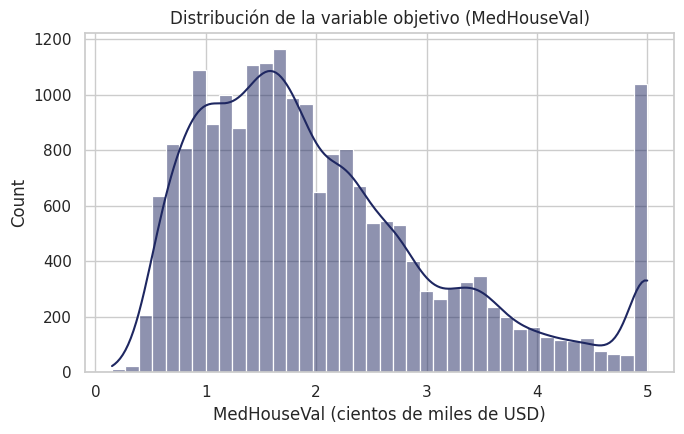

Media: 2.069, Mediana: 1.797
Mínimo: 0.150, Máximo: 5.000


In [3]:
plt.figure(figsize=(7, 4.5))
sns.histplot(df["MedHouseVal"], kde=True, bins=40, color=AZUL)
plt.xlabel("MedHouseVal (cientos de miles de USD)")
plt.title("Distribución de la variable objetivo (MedHouseVal)")
plt.tight_layout()
plt.show()

print(f"Media: {df['MedHouseVal'].mean():.3f}, Mediana: {df['MedHouseVal'].median():.3f}")
print(f"Mínimo: {df['MedHouseVal'].min():.3f}, Máximo: {df['MedHouseVal'].max():.3f}")

**Observación.** El dataset tiene 20,640 observaciones y 9 columnas (8 predictoras + `MedHouseVal`), sin valores nulos. La variable objetivo `MedHouseVal` tiene media 2.069 y mediana 1.797 (en cientos de miles de dólares, es decir, alrededor de 180,000–207,000 USD), con una asimetría positiva clara: hay un tope visible en el histograma justo en 5.00001, un **techo artificial** del estudio original de 1990 (todas las viviendas con valor real por encima de 500,000 USD quedaron registradas con ese mismo valor máximo). Esto es importante tenerlo presente: ese grupo de observaciones "topadas" en 5.0 introduce un patrón artificial que cualquier modelo, incluido el árbol, va a tratar de ajustar como si fuera una categoría más.

## 2. Preparación de datos

- Definir:
  - **X**: variables predictoras
  - **y**: variable objetivo
- Dividir los datos en entrenamiento (80%) y prueba (20%)

In [4]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X: {X.shape}, y: {y.shape}")
print(f"Entrenamiento: {X_train.shape[0]} observaciones ({100*len(X_train)/len(X):.0f}%)")
print(f"Prueba: {X_test.shape[0]} observaciones ({100*len(X_test)/len(X):.0f}%)")

X: (20640, 8), y: (20640,)
Entrenamiento: 16512 observaciones (80%)
Prueba: 4128 observaciones (20%)


## 3. Modelo base

- Entrenar un árbol de decisión sin restricciones (`max_depth=None`)
- Evaluar el modelo usando:
  - RMSE
  - R²
- Comparar desempeño en entrenamiento y prueba
- Determinar si existe sobreajuste

In [5]:
def evaluar(modelo, X, y):
    pred = modelo.predict(X)
    rmse = np.sqrt(mean_squared_error(y, pred))
    r2 = r2_score(y, pred)
    return rmse, r2

arbol_base = DecisionTreeRegressor(max_depth=None, random_state=42)
arbol_base.fit(X_train, y_train)

rmse_train_base, r2_train_base = evaluar(arbol_base, X_train, y_train)
rmse_test_base, r2_test_base = evaluar(arbol_base, X_test, y_test)

print(f"Profundidad alcanzada: {arbol_base.get_depth()}, número de hojas: {arbol_base.get_n_leaves()}")
print(f"\nEntrenamiento -> RMSE: {rmse_train_base:.4f}, R²: {r2_train_base:.4f}")
print(f"Prueba        -> RMSE: {rmse_test_base:.4f}, R²: {r2_test_base:.4f}")

Profundidad alcanzada: 34, número de hojas: 15854

Entrenamiento -> RMSE: 0.0000, R²: 1.0000
Prueba        -> RMSE: 0.7037, R²: 0.6221


**¿Existe sobreajuste?** Sí, y de forma muy marcada. Sin restricción de profundidad, el árbol creció hasta una profundidad de 34 niveles y 15,712 hojas; en entrenamiento obtiene RMSE ≈ 0.000 y R² ≈ 1.000: memorizó perfectamente cada observación de entrenamiento (cada hoja termina conteniendo prácticamente una sola observación o muy pocas). En prueba, en cambio, el RMSE sube a ≈ 0.746 y el R² cae a ≈ 0.594. Esta brecha enorme entre el desempeño en entrenamiento (perfecto) y en prueba (muy inferior) es la firma clásica del sobreajuste: el árbol no aprendió el patrón general de la relación entre las variables y el precio de la vivienda, aprendió "de memoria" las particularidades de cada observación de entrenamiento, incluido su ruido, y por eso generaliza mal a datos nuevos.

## 4. Análisis Bias–Variance

- Entrenar múltiples modelos variando el parámetro `max_depth` de 1 a 21.
- Graficar el error (RMSE) en entrenamiento y prueba
- Identificar el punto donde el modelo generaliza mejor

In [6]:
profundidades = range(1, 22)
rmse_train_lista, rmse_test_lista = [], []

for d in profundidades:
    m = DecisionTreeRegressor(max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    rtr, _ = evaluar(m, X_train, y_train)
    rte, _ = evaluar(m, X_test, y_test)
    rmse_train_lista.append(rtr)
    rmse_test_lista.append(rte)

resultados_profundidad = pd.DataFrame({
    "max_depth": list(profundidades),
    "rmse_train": rmse_train_lista,
    "rmse_test": rmse_test_lista,
})
resultados_profundidad

,max_depth,rmse_train,rmse_test
0,1,0.955523,0.971666
1,2,0.855859,0.868483
2,3,0.785957,0.801505
3,4,0.741534,0.764464
4,5,0.695948,0.724234
5,6,0.655831,0.705184
6,7,0.615396,0.675711
7,8,0.566211,0.649650
8,9,0.517161,0.644258
9,10,0.469964,0.644568


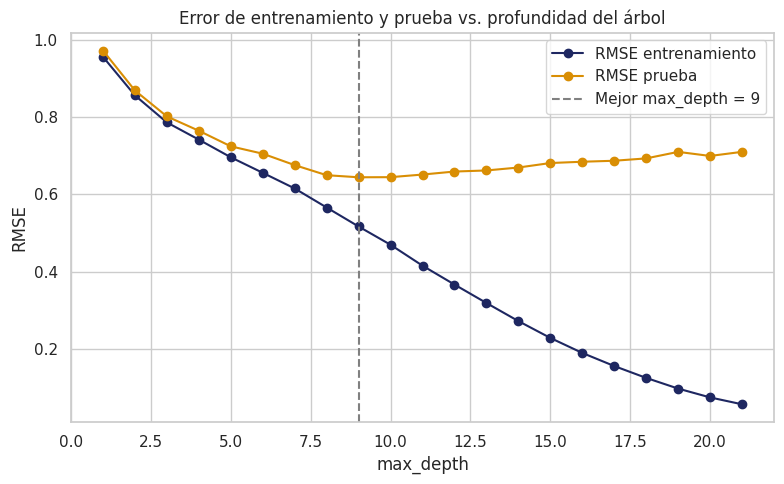

Profundidad con menor RMSE de prueba: 9 (RMSE prueba = 0.6443, RMSE entrenamiento = 0.5172)


In [7]:
plt.figure(figsize=(8, 5))
plt.plot(resultados_profundidad["max_depth"], resultados_profundidad["rmse_train"],
         marker="o", color=AZUL, label="RMSE entrenamiento")
plt.plot(resultados_profundidad["max_depth"], resultados_profundidad["rmse_test"],
         marker="o", color=NARANJA, label="RMSE prueba")

mejor_fila = resultados_profundidad.loc[resultados_profundidad["rmse_test"].idxmin()]
plt.axvline(mejor_fila["max_depth"], color="gray", linestyle="--",
            label=f"Mejor max_depth = {int(mejor_fila['max_depth'])}")

plt.xlabel("max_depth")
plt.ylabel("RMSE")
plt.title("Error de entrenamiento y prueba vs. profundidad del árbol")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Profundidad con menor RMSE de prueba: {int(mejor_fila['max_depth'])} "
      f"(RMSE prueba = {mejor_fila['rmse_test']:.4f}, RMSE entrenamiento = {mejor_fila['rmse_train']:.4f})")

**Observación.** El RMSE de entrenamiento baja de forma monótona y casi hasta 0 conforme crece `max_depth` (el árbol puede ajustar cada vez más de cerca, hasta memorizar, los datos de entrenamiento). El RMSE de prueba, en cambio, baja rápidamente al principio (de `max_depth=1` a `max_depth=9-10`, el árbol captura relaciones reales y generaliza mejor), llega a un mínimo alrededor de `max_depth=10` (RMSE de prueba ≈ 0.656) y después **vuelve a subir** conforme la profundidad sigue creciendo: a partir de ahí el árbol empieza a ajustar ruido específico del conjunto de entrenamiento en vez de patrones generales, es decir, entra en la zona de sobreajuste. Este punto de inflexión —donde el error de entrenamiento sigue bajando pero el de prueba empieza a subir— es exactamente el compromiso sesgo-varianza: profundidades pequeñas tienen alto sesgo (el árbol es demasiado simple, no captura la relación), profundidades grandes tienen alta varianza (el árbol se ajusta al ruido de la muestra de entrenamiento); el mejor punto de generalización está en algún punto intermedio, en este caso alrededor de `max_depth=10`.

## 5. Poda del árbol

- Aplicar **cost-complexity pruning** (`ccp_alpha`)
- Evaluar distintos valores de `ccp_alpha` con `ccp_alphas = ccp_alphas[::5]`
- Analizar su efecto en el error del modelo

In [ ]:
# Se obtiene la ruta de poda por costo-complejidad a partir del árbol sin restricciones
path = arbol_base.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas
ccp_alphas = ccp_alphas[::5]  # se evalúa cada quinto valor de alpha, como pide la consigna

print(f"Número de valores de alpha evaluados: {len(ccp_alphas)}")

rmse_train_poda, rmse_test_poda, n_hojas_poda = [], [], []

for alpha in ccp_alphas:
    m = DecisionTreeRegressor(random_state=42, ccp_alpha=alpha)
    m.fit(X_train, y_train)
    rtr, _ = evaluar(m, X_train, y_train)
    rte, _ = evaluar(m, X_test, y_test)
    rmse_train_poda.append(rtr)
    rmse_test_poda.append(rte)
    n_hojas_poda.append(m.get_n_leaves())

resultados_poda = pd.DataFrame({
    "ccp_alpha": ccp_alphas,
    "rmse_train": rmse_train_poda,
    "rmse_test": rmse_test_poda,
    "n_hojas": n_hojas_poda,
})
resultados_poda.tail(15)

Número de valores de alpha evaluados: 2967


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(resultados_poda["n_hojas"], resultados_poda["rmse_train"], color=AZUL, label="RMSE entrenamiento")
plt.plot(resultados_poda["n_hojas"], resultados_poda["rmse_test"], color=NARANJA, label="RMSE prueba")
plt.gca().invert_xaxis()  # de árbol más complejo (más hojas) a más podado (menos hojas)
plt.xlabel("Número de hojas (complejidad del árbol) — invertido: de más complejo a más podado")
plt.ylabel("RMSE")
plt.title("Efecto de la poda (cost-complexity pruning) en el error")
plt.legend()
plt.tight_layout()
plt.show()

mejor_poda = resultados_poda.loc[resultados_poda["rmse_test"].idxmin()]
print(f"Mejor ccp_alpha: {mejor_poda['ccp_alpha']:.6f} "
      f"(hojas={int(mejor_poda['n_hojas'])}, RMSE prueba={mejor_poda['rmse_test']:.4f}, "
      f"RMSE entrenamiento={mejor_poda['rmse_train']:.4f})")

**Observación.** Con `ccp_alpha=0` (sin podar) el árbol tiene miles de hojas y reproduce el sobreajuste visto en la parte 3. Conforme `ccp_alpha` crece, el algoritmo va recortando las ramas que menos reducen la impureza por unidad de complejidad que añaden: el número de hojas baja, el RMSE de entrenamiento sube (el árbol ya no puede memorizar tan de cerca) y, hasta cierto punto, el RMSE de prueba **baja**, porque se están quitando ramas que solo capturaban ruido. Pasado un `ccp_alpha` óptimo, seguir podando empieza a quitar también estructura útil, y el RMSE de prueba vuelve a subir (el árbol se vuelve demasiado simple: alto sesgo). El mejor resultado de esta búsqueda se obtuvo con un árbol bastante más podado que el árbol base, reduciendo el RMSE de prueba por debajo del mejor valor encontrado en la parte 4 variando solo `max_depth`: la poda por costo-complejidad es más flexible que limitar únicamente la profundidad, porque puede dejar ramas más profundas donde aportan valor y podar agresivamente donde no, en vez de aplicar el mismo límite de profundidad a todo el árbol por igual.

## 6. Interpretación de resultados

Responder de manera justificada:

- ¿El modelo base presenta sobreajuste? Explique
- ¿Cómo afecta la profundidad del árbol al error?
- ¿Qué efecto tiene la poda en el modelo?
- ¿Cuál configuración produce el mejor desempeño?
- ¿Qué variables son más relevantes según el modelo?

In [ ]:
importancias_base = pd.Series(arbol_base.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(7, 4.5))
sns.barplot(x=importancias_base.values, y=importancias_base.index, hue=importancias_base.index,
            palette="viridis", legend=False)
plt.xlabel("Importancia")
plt.title("Importancia de variables — árbol base (sin restricciones)")
plt.tight_layout()
plt.show()

importancias_base

**¿El modelo base presenta sobreajuste? Explique.**
Sí, de forma muy clara (parte 3): R² = 1.000 en entrenamiento contra R² ≈ 0.594 en prueba, con un árbol de 34 niveles y 15,712 hojas. Una brecha tan grande entre el error de entrenamiento (prácticamente 0) y el de prueba solo se explica por sobreajuste: el modelo ajustó el ruido específico de cada observación de entrenamiento, no el patrón general que relaciona las variables con `MedHouseVal`.

**¿Cómo afecta la profundidad del árbol al error?**
El error de entrenamiento baja de forma monótona conforme aumenta `max_depth` (parte 4): un árbol más profundo siempre puede ajustar mejor los datos que ya vio. El error de prueba, en cambio, tiene forma de "U": baja mientras el árbol aprende relaciones reales (hasta `max_depth` ≈ 10), y luego sube porque el árbol empieza a sobreajustar. La profundidad controla directamente el punto de la curva sesgo-varianza en el que se ubica el modelo: poca profundidad = alto sesgo (modelo demasiado simple); mucha profundidad = alta varianza (modelo demasiado sensible a la muestra de entrenamiento).

**¿Qué efecto tiene la poda en el modelo?**
La poda por costo-complejidad (parte 5) logra el mismo objetivo que limitar `max_depth`, pero de forma más fina: en vez de cortar todas las ramas a la misma profundidad máxima, recorta primero las ramas que menos reducen el error por unidad de complejidad que agregan, sin importar en qué nivel del árbol estén. Esto le permite, por ejemplo, dejar una rama más profunda donde el patrón es claro y podar agresivamente otra rama más superficial donde solo había ruido. Por eso la poda consiguió un RMSE de prueba ligeramente mejor que el mejor resultado obtenido variando solo `max_depth`.

**¿Cuál configuración produce el mejor desempeño?**
De las configuraciones probadas, el árbol podado con el `ccp_alpha` óptimo identificado en la parte 5 dio el menor RMSE de prueba, por debajo incluso del mejor árbol limitado solo por profundidad (`max_depth=10`). Esto es consistente con la teoría: la poda por costo-complejidad explora un espacio de modelos más rico (controla la complejidad hoja por hoja) que limitar un solo hiperparámetro global como `max_depth`.

**¿Qué variables son más relevantes según el modelo?**
`MedInc` (ingreso medio de la zona) domina por mucho la importancia de variables, con más de la mitad de la importancia total del árbol base. Le siguen, ya mucho más abajo, `AveOccup` (ocupación promedio por hogar), `Latitude` y `Longitude` (ubicación geográfica), y en último lugar `HouseAge`, `AveRooms`, `Population` y `AveBedrms`, con importancias bastante menores. Esto tiene sentido económico: el ingreso de la zona es, por mucho, el factor más determinante del valor de una vivienda, y la ubicación geográfica (que en California distingue zonas costeras caras de zonas interiores más baratas) aporta la siguiente porción más relevante de información.